# TP - Clasificación de Texto con MLP (20 Newsgroups)
### Redes Neuronales / Deep Learning

Continuación del TP de Regresión Softmax: se reemplaza el modelo lineal por un **MLP** (perceptrón multicapa) y se buscan con **Optuna** (con *pruning*) los hiperparámetros de preprocesamiento, arquitectura y optimizador.

**Contenido**
1. Setup, datos y preprocesamiento (igual que el TP anterior).
2. Modelo MLP configurable (1 a 3 capas ocultas, neuronas por capa, función de activación).
3. Búsqueda con Optuna: preprocesamiento, `lr`, `batch_size`, arquitectura y optimizador (Adam, RMSprop, SGD) con sus momentos de orden 1 y 2. Incluye *pruning*.
4. Análisis de todos los trials: performance y tiempos.
5. Experimento controlado de SGD con distintos learning rates.
6. Entrenamiento final con los mejores hiperparámetros y evaluación en test.
7. Experimento de overfitting (MLP grande, aparte de la búsqueda).
8. Comparación con Regresión Softmax, con el mismo presupuesto de búsqueda.
9. Variabilidad entre semillas.

## 0. Setup

In [1]:
!pip install -q mlflow optuna

In [2]:
import os
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

import mlflow
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)
if device.type == "cpu":
    print("ATENCIÓN: sin GPU el entrenamiento va a ser bastante más lento.")

Usando dispositivo: cuda


In [3]:
for recurso in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab"]:
    nltk.download(recurso, quiet=True)

## Configuración general

Valores elegidos para que la búsqueda sea rápida. Se pueden aumentar si hay tiempo.

In [4]:
N_TRIALS = 30            # cantidad máxima de trials de Optuna
TIMEOUT_S = 20 * 60      # corta la búsqueda a los 20 minutos aunque no haya terminado
EPOCHS_SEARCH = 8        # épocas por trial (el pruning corta antes los trials malos)
EPOCHS_OVERFIT = 25      # épocas del experimento de overfitting
EPOCHS_SOFTMAX = 20      # épocas de la regresión softmax de comparación
EVAL_BATCH = 1024        # tamaño de lote para evaluar (no afecta el entrenamiento)

mlflow.end_run()  # por si quedó algún run abierto de una ejecución anterior
mlflow.set_experiment("mlp_20newsgroups")

2026/11/19 01:18:25 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/19 01:18:25 INFO mlflow.store.db.utils: Updating database tables
2026/11/19 01:18:32 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1795051112006, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1795051112006, lifecycle_stage='active', name='mlp_20newsgroups', tags={}, trace_location=None, workspace='default'>

## 1. Datos: 20 Newsgroups

In [5]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
y_train_full = np.array(newsgroups_train.target)
y_test = np.array(newsgroups_test.target)
print(f"Clases: {NUM_CLASSES} | Train: {len(y_train_full)} | Test: {len(y_test)}")

Clases: 20 | Train: 11314 | Test: 7532


## 2. Preprocesamiento y vectorización (del TP anterior)

In [6]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)


def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

In [7]:
# Precalculamos el preprocesamiento para las 6 combinaciones (es lo más lento del pipeline)
t0 = time.perf_counter()
preprocessed_cache = {}
for remove_sw in [False, True]:
    for norm in ["none", "stem", "lemmatize"]:
        train_proc = [preprocess_text(t, remove_sw, norm) for t in newsgroups_train.data]
        test_proc = [preprocess_text(t, remove_sw, norm) for t in newsgroups_test.data]
        preprocessed_cache[(remove_sw, norm)] = (train_proc, test_proc)
        print("  listo:", (remove_sw, norm))
print(f"Preprocesamiento total: {time.perf_counter() - t0:.1f} s")

  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')
Preprocesamiento total: 203.2 s


In [8]:
# Partición train/validación fija para toda la búsqueda (misma que en el TP anterior)
idx_tr, idx_val = train_test_split(
    np.arange(len(y_train_full)), test_size=0.2, random_state=SEED, stratify=y_train_full
)
y_tr, y_val = y_train_full[idx_tr], y_train_full[idx_val]

# Cache de matrices TF-IDF (dispersas) para no revectorizar configuraciones repetidas
vectorized_cache = {}


def get_search_features(remove_sw, norm, ngram, max_features, min_df):
    key = (remove_sw, norm, ngram, max_features, min_df)
    if key not in vectorized_cache:
        train_texts, _ = preprocessed_cache[(remove_sw, norm)]
        tr_texts = [train_texts[i] for i in idx_tr]
        val_texts = [train_texts[i] for i in idx_val]
        X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram, max_features, min_df)
        vectorized_cache[key] = (X_tr, X_val)
    return vectorized_cache[key]


def to_device(X, y):
    # Matriz dispersa -> tensor denso en el dispositivo (los datos entran en memoria)
    X_t = torch.tensor(X.toarray(), dtype=torch.float32, device=device)
    y_t = torch.tensor(y, dtype=torch.long, device=device)
    return X_t, y_t

## 3. Modelo: MLP configurable

In [9]:
ACTIVATIONS = {
    "relu": nn.ReLU,
    "tanh": nn.Tanh,
    "leaky_relu": nn.LeakyReLU,
    "gelu": nn.GELU,
}


class MLP(nn.Module):
    """Capas ocultas Linear + activación, y una capa de salida que devuelve logits.
    Con hidden_sizes=[] es una regresión softmax (una sola capa lineal)."""

    def __init__(self, input_dim, hidden_sizes, num_classes, activation="relu"):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_sizes:
            layers += [nn.Linear(prev, h), ACTIVATIONS[activation]()]
            prev = h
        layers.append(nn.Linear(prev, num_classes))  # sin softmax: CrossEntropyLoss lo incluye
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Sanity check
_m = MLP(50, [32, 16], 20, "gelu")
assert _m(torch.randn(4, 50)).shape == (4, 20)
print(_m)
print("Parámetros:", count_params(_m))

MLP(
  (net): Sequential(
    (0): Linear(in_features=50, out_features=32, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=16, out_features=20, bias=True)
  )
)
Parámetros: 2500


In [10]:
def make_optimizer(name, params, lr, opt_kwargs):
    if name == "adam":
        return optim.Adam(params, lr=lr, betas=(opt_kwargs["beta1"], opt_kwargs["beta2"]))
    if name == "rmsprop":
        return optim.RMSprop(params, lr=lr, alpha=opt_kwargs["alpha"], momentum=opt_kwargs["momentum"])
    if name == "sgd":
        return optim.SGD(params, lr=lr, momentum=opt_kwargs["momentum"])
    raise ValueError(name)

## 4. Entrenamiento (con medición de tiempos y soporte de pruning)

In [11]:
criterion = nn.CrossEntropyLoss()


def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def evaluate(model, X, y):
    model.eval()
    total_loss, correct = 0.0, 0
    for i in range(0, len(y), EVAL_BATCH):
        logits = model(X[i:i + EVAL_BATCH])
        total_loss += criterion(logits, y[i:i + EVAL_BATCH]).item() * len(logits)
        correct += (logits.argmax(1) == y[i:i + EVAL_BATCH]).sum().item()
    return total_loss / len(y), correct / len(y)


def train_model(model, X_tr, y_tr, X_val, y_val, optimizer, epochs, batch_size,
                trial=None, run_name="run", verbose=True):
    """Entrena y devuelve el historial por época. Si recibe un trial de Optuna,
    reporta val_acc en cada época y corta el entrenamiento si el pruner lo indica."""
    model.to(device)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    n = len(y_tr)
    for epoch in range(epochs):
        sync()
        t0 = time.perf_counter()
        model.train()
        perm = torch.randperm(n, device=device)
        run_loss, correct = 0.0, 0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = X_tr[idx], y_tr[idx]
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * len(idx)
            correct += (logits.argmax(1) == yb).sum().item()
        sync()
        epoch_time = time.perf_counter() - t0

        val_loss, val_acc = evaluate(model, X_val, y_val)
        hist["train_loss"].append(run_loss / n)
        hist["train_acc"].append(correct / n)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)
        hist["epoch_time"].append(epoch_time)

        if verbose:
            print(f"[{run_name}] ep {epoch + 1}/{epochs} - train_loss {hist['train_loss'][-1]:.4f} "
                  f"train_acc {hist['train_acc'][-1]:.4f} - val_loss {val_loss:.4f} "
                  f"val_acc {val_acc:.4f} - {epoch_time:.2f} s")
        if mlflow.active_run() is not None:
            mlflow.log_metrics({k: hist[k][-1] for k in hist}, step=epoch)

        if trial is not None:
            trial.report(val_acc, epoch)
            if trial.should_prune():
                trial.set_user_attr("history", hist)
                raise optuna.TrialPruned()
    return hist

## 5. Búsqueda de hiperparámetros con Optuna (con pruning)

- **Preprocesamiento (TP anterior):** `remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`.
- **Entrenamiento (TP anterior):** `lr` y `batch_size`. El rango de `lr` depende del optimizador: entre 1e-4 y 0.1 para Adam y RMSprop, y entre 0.01 y 10 para SGD, que necesita valores más altos.
- **Arquitectura:** `n_layers` (1 a 3), `n_units_l{i}` (neuronas de cada capa) y `activation`.
- **Optimizador:** `adam` (`beta1` = momento de orden 1, `beta2` = momento de orden 2), `rmsprop` (`momentum` = orden 1, `alpha` = promedio del gradiente al cuadrado, orden 2) y `sgd` (`momentum` = orden 1).
- **Pruning:** `MedianPruner` corta un trial si en una época queda por debajo de la mediana de los trials anteriores en esa misma época.
- **Objetivo:** la mejor `val_acc` entre las épocas de cada trial. También se guarda en qué época se alcanzó. Elegir la mejor época es levemente optimista, y con 2263 documentos de validación una accuracy tiene un error de muestreo de ≈0.9 puntos.
- La misma función `objective` se usa en la sección 9 para buscar la regresión softmax con el mismo presupuesto.

In [12]:
def objective(trial, model_kind="mlp"):
    # --- Preprocesamiento (TP anterior) ---
    remove_sw = trial.suggest_categorical("remove_stopwords", [False, True])
    norm = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_name = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram = (1, 1) if ngram_name == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])

    # --- Entrenamiento (TP anterior) ---
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # --- Arquitectura ---
    if model_kind == "mlp":
        n_layers = trial.suggest_int("n_layers", 1, 3)
        hidden = [trial.suggest_categorical(f"n_units_l{i}", [64, 128, 256, 512]) for i in range(n_layers)]
        activation = trial.suggest_categorical("activation", list(ACTIVATIONS))
    else:
        hidden, activation = [], "relu"  # sin capas ocultas la activación no se usa

    # --- Optimizador y momentos ---
    opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])
    if opt_name == "sgd":
      lr = trial.suggest_float("lr_sgd", 1e-2, 10.0, log=True)  # SGD necesita lr más altos
    else:
      lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
    if opt_name == "adam":
        opt_kwargs = {"beta1": trial.suggest_float("adam_beta1", 0.8, 0.99),
                      "beta2": trial.suggest_float("adam_beta2", 0.9, 0.9999)}
    elif opt_name == "rmsprop":
        opt_kwargs = {"alpha": trial.suggest_float("rmsprop_alpha", 0.8, 0.999),
                      "momentum": trial.suggest_float("rmsprop_momentum", 0.0, 0.9)}
    else:
        opt_kwargs = {"momentum": trial.suggest_float("sgd_momentum", 0.0, 0.95)}

    # --- Datos ---
    t0 = time.perf_counter()
    X_tr_sp, X_val_sp = get_search_features(remove_sw, norm, ngram, max_features, min_df)
    X_tr, y_tr_t = to_device(X_tr_sp, y_tr)
    X_val, y_val_t = to_device(X_val_sp, y_val)
    trial.set_user_attr("prep_time_s", time.perf_counter() - t0)

    # --- Modelo y entrenamiento ---
    torch.manual_seed(SEED + trial.number)
    model = MLP(X_tr.shape[1], hidden, NUM_CLASSES, activation)
    optimizer = make_optimizer(opt_name, model.parameters(), lr, opt_kwargs)
    trial.set_user_attr("n_params", count_params(model))

    with mlflow.start_run(run_name=f"{model_kind}_trial_{trial.number}"):
        mlflow.log_params(trial.params)
        t1 = time.perf_counter()
        try:
            hist = train_model(model, X_tr, y_tr_t, X_val, y_val_t, optimizer, EPOCHS_SEARCH,
                               batch_size, trial=trial, run_name=f"{model_kind}_trial_{trial.number}", verbose=False)
        finally:
            trial.set_user_attr("train_time_s", time.perf_counter() - t1)
            mlflow.log_metric("train_time_s", time.perf_counter() - t1)

    best_epoch = int(np.argmax(hist["val_acc"])) + 1
    trial.set_user_attr("history", hist)
    trial.set_user_attr("best_epoch", best_epoch)
    return max(hist["val_acc"])

In [13]:
optuna.logging.set_verbosity(optuna.logging.INFO)
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),
)
t0 = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT_S)
search_time = time.perf_counter() - t0

states = pd.Series([t.state.name for t in study.trials]).value_counts()
print(f"\nBúsqueda: {search_time:.1f} s | trials por estado:\n{states.to_string()}")
print("\nMejor val_acc:", round(study.best_value, 4))
print("Mejor época:", study.best_trial.user_attrs["best_epoch"])
print("Mejores hiperparámetros:", study.best_params)

[I 2026-11-19 01:22:10,557] A new study created in memory with name: no-name-eb9722cb-7601-4029-acab-c3aa8a16846b
[I 2026-11-19 01:22:22,083] Trial 0 finished with value: 0.6159964648696421 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'batch_size': 32, 'n_layers': 1, 'n_units_l0': 512, 'activation': 'gelu', 'optimizer': 'adam', 'lr': 0.005987474910461402, 'adam_beta1': 0.8088255784167996, 'adam_beta2': 0.9606937307049537}. Best is trial 0 with value: 0.6159964648696421.
[I 2026-11-19 01:22:25,323] Trial 1 finished with value: 0.11665930181175431 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 5, 'batch_size': 64, 'n_layers': 2, 'n_units_l0': 256, 'n_units_l1': 64, 'activation': 'gelu', 'optimizer': 'sgd', 'lr_sgd': 0.11756010900231852, 'sgd_momentum': 0.26688778420301174}. Best is trial 0 with value: 0.6159964648696421.
[I 2026-1


Búsqueda: 103.1 s | trials por estado:
COMPLETE    21
PRUNED       9

Mejor val_acc: 0.7229
Mejor época: 1
Mejores hiperparámetros: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 5, 'batch_size': 128, 'n_layers': 1, 'n_units_l0': 512, 'activation': 'leaky_relu', 'optimizer': 'adam', 'lr': 0.010729789938530885, 'adam_beta1': 0.8354292857301224, 'adam_beta2': 0.9454772574047643}


## 6. Análisis de todos los trials: performance y tiempos

In [14]:
rows = []
for t in study.trials:
    if t.state.name not in ("COMPLETE", "PRUNED"):
        continue
    h = t.user_attrs.get("history", {})
    epochs_run = len(h.get("val_acc", []))
    if epochs_run == 0:
        continue
    p = t.params
    rows.append({
        "trial": t.number,
        "estado": t.state.name,
        "best_val_acc": max(h["val_acc"]),
        "best_epoch": int(np.argmax(h["val_acc"])) + 1,
        "train_acc_final": h["train_acc"][-1],
        "epocas": epochs_run,
        "t_entrenamiento_s": t.user_attrs.get("train_time_s", np.nan),
        "t_por_epoca_s": float(np.mean(h["epoch_time"])),
        "n_params": t.user_attrs.get("n_params"),
        "optimizer": p["optimizer"],
        "activation": p["activation"],
        "n_layers": p["n_layers"],
        "neuronas": "-".join(str(p[f"n_units_l{i}"]) for i in range(p["n_layers"])),
        "lr": p.get("lr", p.get("lr_sgd")),
        "batch_size": p["batch_size"],
        "max_features": p["max_features"],
        "ngram": p["ngram_range"],
        "stopwords": p["remove_stopwords"],
        "norm": p["normalization"],
    })
df_trials = pd.DataFrame(rows).sort_values("best_val_acc", ascending=False).reset_index(drop=True)
df_trials["gap_train_val"] = df_trials["train_acc_final"] - df_trials["best_val_acc"]
pd.set_option("display.width", 250)
df_trials.round(4)

,trial,estado,best_val_acc,best_epoch,train_acc_final,epocas,t_entrenamiento_s,t_por_epoca_s,n_params,optimizer,activation,n_layers,neuronas,lr,batch_size,max_features,ngram,stopwords,norm,gap_train_val
0,28,COMPLETE,0.7229,1,0.9746,8,1.8784,0.2134,5130772,adam,leaky_relu,1,512,0.0107,128,10000,1gram,False,lemmatize,0.2517
1,29,COMPLETE,0.7048,1,0.9730,8,1.7785,0.2034,5130772,adam,leaky_relu,1,512,0.0306,128,10000,1gram,False,none,0.2682
2,16,COMPLETE,0.7044,1,0.9706,8,1.2854,0.1440,2570772,adam,leaky_relu,1,512,0.0115,128,5000,1gram,True,lemmatize,0.2662
3,22,COMPLETE,0.7035,1,0.9726,8,1.9476,0.2253,5393428,adam,leaky_relu,2,512-512,0.0065,128,10000,1gram,True,lemmatize,0.2691
4,17,COMPLETE,0.7030,3,0.9708,8,0.9309,0.1015,321364,adam,leaky_relu,1,64,0.0090,128,5000,1gram,True,lemmatize,0.2678
5,14,COMPLETE,0.7022,8,0.8029,8,0.9406,0.1043,321364,adam,leaky_relu,1,64,0.0008,128,5000,1gram,True,lemmatize,0.1007
6,27,COMPLETE,0.6947,2,0.9699,8,7.3225,0.8951,5393428,adam,gelu,2,512-512,0.0033,32,10000,1gram,True,lemmatize,0.2753
7,2,COMPLETE,0.6832,5,0.9545,8,1.0705,0.1194,341844,adam,leaky_relu,2,64-256,0.0019,128,5000,1gram,False,lemmatize,0.2713
8,21,COMPLETE,0.6739,1,0.9701,8,1.2888,0.1456,2570772,adam,leaky_relu,1,512,0.0343,128,5000,1gram,True,lemmatize,0.2962
9,25,COMPLETE,0.6699,2,0.9686,8,2.0655,0.2401,5417300,adam,leaky_relu,3,512-512-64,0.0057,128,10000,1_2gram,True,stem,0.2987


In [15]:
# Promedio de la mejor val_acc por cada hiperparámetro (solo trials completos)
completos = df_trials[df_trials["estado"] == "COMPLETE"]
for col in ["optimizer", "activation", "n_layers", "batch_size", "max_features", "ngram", "stopwords", "norm"]:
    resumen = completos.groupby(col).agg(n=("trial", "count"),
                                         val_acc_media=("best_val_acc", "mean"),
                                         val_acc_max=("best_val_acc", "max"),
                                         t_por_epoca_media=("t_por_epoca_s", "mean"))
    print(f"\n=== {col} ===")
    print(resumen.round(4).to_string())


=== optimizer ===
            n  val_acc_media  val_acc_max  t_por_epoca_media
optimizer                                                   
adam       14         0.6843       0.7229             0.2467
rmsprop     6         0.6343       0.6620             0.1344
sgd         1         0.1167       0.1167             0.2032

=== activation ===
             n  val_acc_media  val_acc_max  t_por_epoca_media
activation                                                   
gelu         6         0.5629       0.6947             0.3488
leaky_relu  13         0.6820       0.7229             0.1530
relu         1         0.5935       0.5935             0.1558
tanh         1         0.6659       0.6659             0.2254

=== n_layers ===
          n  val_acc_media  val_acc_max  t_por_epoca_media
n_layers                                                  
1         9         0.6825       0.7229             0.1838
2         7         0.5943       0.7035             0.2746
3         5         0.6401    

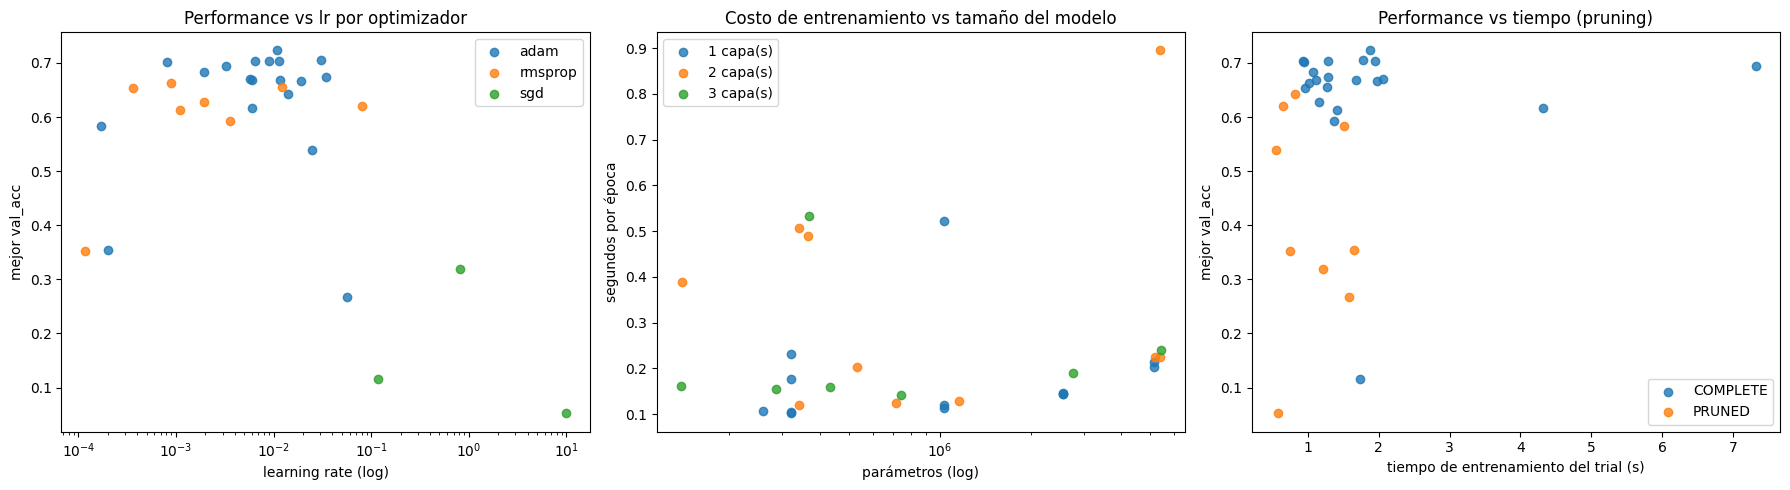

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Performance vs learning rate, por optimizador
for opt_name, g in df_trials.groupby("optimizer"):
    axes[0].scatter(g["lr"], g["best_val_acc"], label=opt_name, alpha=0.8)
axes[0].set_xscale("log")
axes[0].set_xlabel("learning rate (log)")
axes[0].set_ylabel("mejor val_acc")
axes[0].set_title("Performance vs lr por optimizador")
axes[0].legend()

# 2) Tiempo por época vs cantidad de parámetros
for n_l, g in df_trials.groupby("n_layers"):
    axes[1].scatter(g["n_params"], g["t_por_epoca_s"], label=f"{n_l} capa(s)", alpha=0.8)
axes[1].set_xscale("log")
axes[1].set_xlabel("parámetros (log)")
axes[1].set_ylabel("segundos por época")
axes[1].set_title("Costo de entrenamiento vs tamaño del modelo")
axes[1].legend()

# 3) Performance vs tiempo total de entrenamiento (completos vs podados)
for estado, g in df_trials.groupby("estado"):
    axes[2].scatter(g["t_entrenamiento_s"], g["best_val_acc"], label=estado, alpha=0.8)
axes[2].set_xlabel("tiempo de entrenamiento del trial (s)")
axes[2].set_ylabel("mejor val_acc")
axes[2].set_title("Performance vs tiempo (pruning)")
axes[2].legend()

plt.tight_layout()
plt.show()

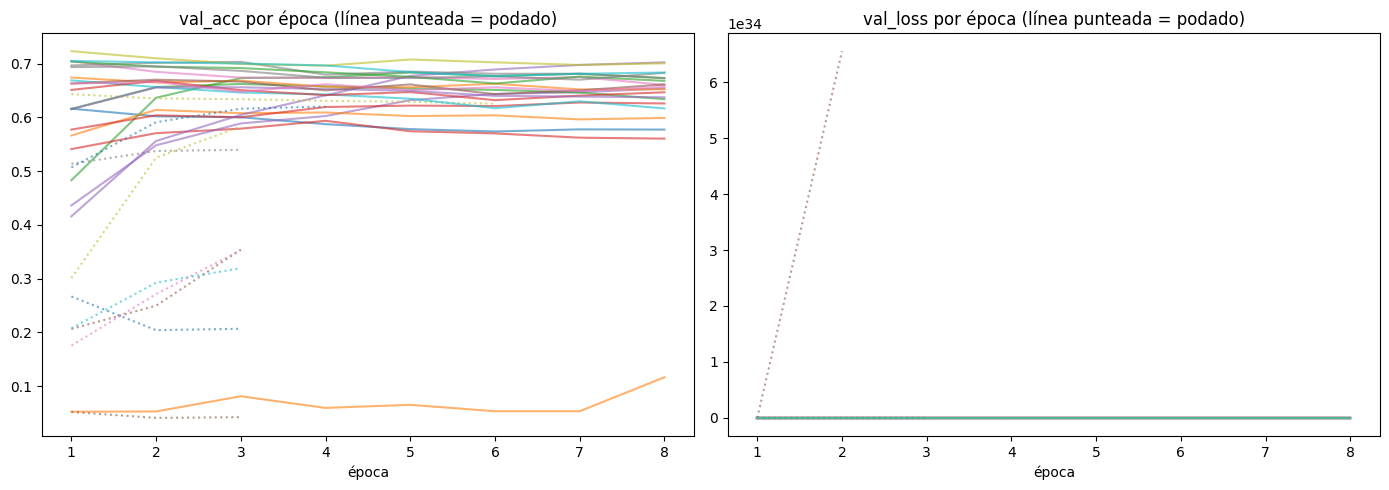

In [17]:
# Curvas de validación de todos los trials: los podados se ven como curvas cortadas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for t in study.trials:
    h = t.user_attrs.get("history")
    if not h:
        continue
    estilo = "-" if t.state.name == "COMPLETE" else ":"
    ep = range(1, len(h["val_acc"]) + 1)
    axes[0].plot(ep, h["val_acc"], estilo, alpha=0.6)
    axes[1].plot(ep, h["val_loss"], estilo, alpha=0.6)
axes[0].set_title("val_acc por época (línea punteada = podado)")
axes[1].set_title("val_loss por época (línea punteada = podado)")
for ax in axes:
    ax.set_xlabel("época")
plt.tight_layout()
plt.show()

In [18]:
# Tiempo ahorrado por el pruning (estimado con el tiempo por época de cada trial podado)
podados = df_trials[df_trials["estado"] == "PRUNED"]
ahorro = ((EPOCHS_SEARCH - podados["epocas"]) * podados["t_por_epoca_s"]).sum()
print(f"Trials podados: {len(podados)} de {len(df_trials)}")
print(f"Épocas evitadas: {(EPOCHS_SEARCH - podados['epocas']).sum()}")
print(f"Tiempo de entrenamiento ahorrado (estimado): {ahorro:.1f} s")
print(f"Tiempo total de entrenamiento de los trials: {df_trials['t_entrenamiento_s'].sum():.1f} s")

Trials podados: 9 de 30
Épocas evitadas: 41
Tiempo de entrenamiento ahorrado (estimado): 13.3 s
Tiempo total de entrenamiento de los trials: 47.8 s


In [19]:
# Experimento controlado: SGD (momentum 0.9) con el mejor preprocesamiento y arquitectura,
# cambiando solo el learning rate
bp = study.best_params
SGD_LRS = [0.01, 0.1, 0.3, 1.0, 3.0, 10.0]
sgd_ngram = (1, 1) if bp["ngram_range"] == "1gram" else (1, 2)
sgd_hidden = [bp[f"n_units_l{i}"] for i in range(bp["n_layers"])]
X_sgd_tr_sp, X_sgd_val_sp = get_search_features(bp["remove_stopwords"], bp["normalization"], sgd_ngram,
                                                bp["max_features"], bp["min_df"])
X_sgd_tr, y_sgd_tr = to_device(X_sgd_tr_sp, y_tr)
X_sgd_val, y_sgd_val = to_device(X_sgd_val_sp, y_val)

sgd_results = {}
for lr_sgd in SGD_LRS:
    torch.manual_seed(SEED)
    model_sgd = MLP(X_sgd_tr.shape[1], sgd_hidden, NUM_CLASSES, bp["activation"])
    opt_sgd = optim.SGD(model_sgd.parameters(), lr=lr_sgd, momentum=0.9)
    t0 = time.perf_counter()
    h = train_model(model_sgd, X_sgd_tr, y_sgd_tr, X_sgd_val, y_sgd_val, opt_sgd,
                    EPOCHS_SEARCH, bp["batch_size"], run_name=f"sgd_lr{lr_sgd}", verbose=False)
    sgd_results[lr_sgd] = {"hist": h, "tiempo_s": time.perf_counter() - t0}
    print(f"lr={lr_sgd:<5} -> mejor val_acc {max(h['val_acc']):.4f} "
          f"(época {int(np.argmax(h['val_acc'])) + 1}) | val_loss final {h['val_loss'][-1]:.3f} "
          f"| {sgd_results[lr_sgd]['tiempo_s']:.1f} s")
print(f"\nReferencia: mejor trial de Optuna ({bp['optimizer']}): {study.best_value:.4f}")

lr=0.01  -> mejor val_acc 0.2691 (época 8) | val_loss final 2.977 | 1.1 s
lr=0.1   -> mejor val_acc 0.6014 (época 8) | val_loss final 1.519 | 1.1 s
lr=0.3   -> mejor val_acc 0.6717 (época 8) | val_loss final 1.136 | 1.1 s
lr=1.0   -> mejor val_acc 0.6584 (época 7) | val_loss final 1.626 | 1.1 s
lr=3.0   -> mejor val_acc 0.3226 (época 8) | val_loss final 2.303 | 1.2 s
lr=10.0  -> mejor val_acc 0.0667 (época 1) | val_loss final nan | 1.2 s

Referencia: mejor trial de Optuna (adam): 0.7229


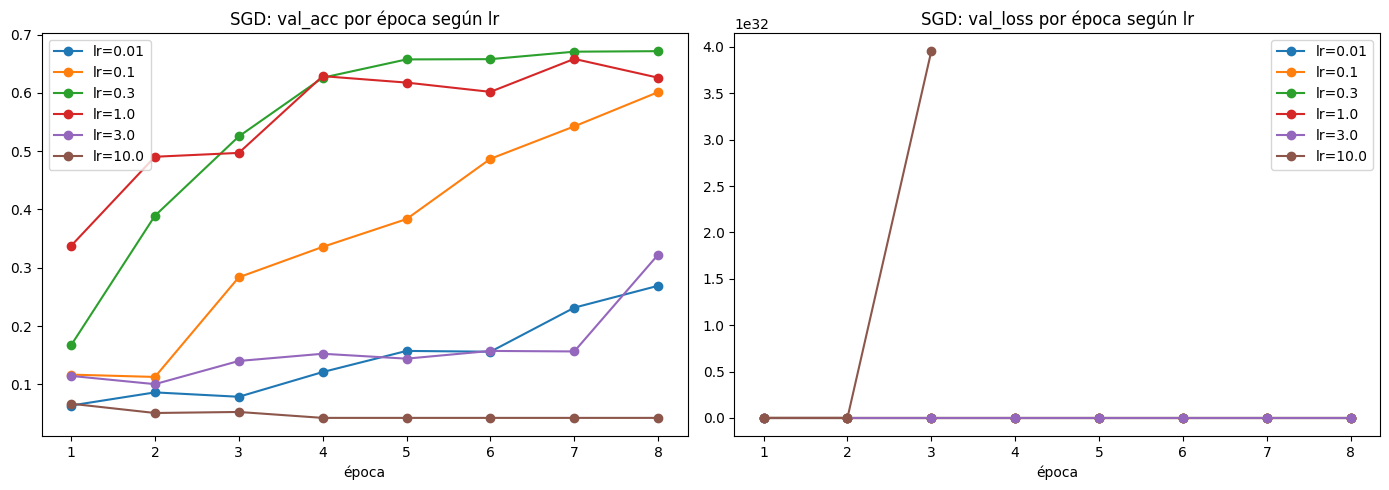

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for lr_sgd, r in sgd_results.items():
    ep = range(1, len(r["hist"]["val_acc"]) + 1)
    axes[0].plot(ep, r["hist"]["val_acc"], marker="o", label=f"lr={lr_sgd}")
    axes[1].plot(ep, r["hist"]["val_loss"], marker="o", label=f"lr={lr_sgd}")
axes[0].set_title("SGD: val_acc por época según lr")
axes[1].set_title("SGD: val_loss por época según lr")
for ax in axes:
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()

## Experimento controlado: SGD con distintos learning rates

Mismo preprocesamiento y arquitectura que el mejor trial, SGD con momentum 0.9 y 8 épocas, cambiando solo el `lr`:

| lr | Mejor val_acc | Época |
|---|---|---|
| 0.01 | 0.269 | 8 |
| 0.1 | 0.601 | 8 |
| 0.3 | 0.672 | 8 |
| 1 | 0.658 | 7 |
| 3 | 0.323 | 8 |
| 10 | 0.067 | 1 (diverge, la loss da `nan`) |

- **SGD sí aprende**, pero necesita un `lr` unas 30 veces mayor que Adam (≈0.3 contra ≈0.01). Con el rango de la entrega anterior (tope 0.1) quedaba en el borde inferior de la zona útil.
- Con `lr` chico aprende muy lento y con `lr` demasiado grande diverge. Como se vio en clase, hay que distinguir un modelo que no puede aprender de un learning rate mal elegido.
- **Converge más lento que Adam:** con `lr=0.3` seguía mejorando en la época 8 y llegó a 0.672, mientras que Adam alcanzó 0.723 en la primera época. Adam ajusta el paso de cada peso con el segundo momento del gradiente, por eso depende menos de la escala del `lr`.
- Cada entrenamiento de 8 épocas tardó ≈1.1 s, igual para todos los `lr`.
- En la búsqueda, SGD se probó solo 3 veces: con `lr≈0.12` quedó en 0.12, con `lr≈0.80` fue podado mientras aprendía (0.32 en la época 3) y con `lr≈9.8` divergió.

## Análisis de la búsqueda

Se probaron 30 configuraciones: 21 terminaron y 9 se cortaron por pruning. La mejor (val_acc 0.7229) es una red de 1 capa de 512 neuronas con LeakyReLU y Adam (`lr≈0.011`, `batch_size=128`), que alcanzó su mejor resultado en la primera época.

- **Capas:** el mejor modelo tiene 1 capa. En promedio, los trials completos dan 0.68 con 1 capa, 0.59 con 2 y 0.64 con 3. Más capas no mejoraron el resultado.
- **Optimizador:** Adam fue el más estable (14 trials completos, media 0.68). RMSprop quedó en 0.63 de media. SGD se probó solo 3 veces, así que la búsqueda no alcanza para evaluarlo. Por eso se hizo el experimento controlado anterior.
- **Learning rate y sobreajuste:** muchos trials con `lr` cercano a 0.01 alcanzan su mejor resultado en las épocas 1 o 2 y después empeoran, con accuracy de train ≈0.97. Los dos trials con `lr` más bajo (≈0.0004 y ≈0.0008) siguieron mejorando hasta la última época y tuvieron la menor diferencia entre train y validación (0.08 y 0.10).
- **Activación:** LeakyReLU aparece en 13 de los 21 trials completos porque Optuna se concentró alrededor de los primeros buenos resultados. ReLU y tanh tuvieron un solo trial completo cada una, así que no se pueden comparar.
- **Preprocesamiento:** con 2000 palabras el resultado medio fue claramente peor (0.55) que con 5000 o 10000 (≈0.69).
- **Tiempos:** lo que más influye es el batch size. Con 32 una época tarda ≈0.7 s y con 128 ≈0.16 s. El tamaño de la red influye menos: con el mismo preprocesamiento y batch 128, pasar de 64 a 512 neuronas (8 veces más parámetros) solo subió el tiempo por época de 0.10 a 0.14 s.
- **Pruning:** se podaron 9 trials y se evitaron 41 épocas, unos 13 s de los 48 s de entrenamiento. La mayor parte del tiempo de búsqueda se usa en preparar los datos de cada trial, no en entrenar.

**Limitaciones.** Con 30 trials muchos hiperparámetros cambian a la vez, así que estas conclusiones son tendencias y no efectos aislados. Además, la búsqueda depende del camino que toma Optuna: en la entrega anterior, el mismo procedimiento encontró otro mejor modelo (1 capa de 64 con tanh, val_acc 0.7428). La diferencia entre las dos búsquedas (≈2 puntos) es mayor que el error de muestreo.

## 7. Entrenamiento final con los mejores hiperparámetros

Se entrena con **todo** el train y se evalúa en test. La cantidad de épocas es la época en la que el mejor trial alcanzó su mejor `val_acc` (equivale a un *early stopping* decidido en validación, sin mirar el test). En la salida de esta celda, `val_loss` y `val_acc` corresponden al **test**.

In [21]:
bp = study.best_params
BEST_EPOCHS = study.best_trial.user_attrs["best_epoch"]
best_ngram = (1, 1) if bp["ngram_range"] == "1gram" else (1, 2)
best_hidden = [bp[f"n_units_l{i}"] for i in range(bp["n_layers"])]
if bp["optimizer"] == "adam":
    best_opt_kwargs = {"beta1": bp["adam_beta1"], "beta2": bp["adam_beta2"]}
elif bp["optimizer"] == "rmsprop":
    best_opt_kwargs = {"alpha": bp["rmsprop_alpha"], "momentum": bp["rmsprop_momentum"]}
else:
    best_opt_kwargs = {"momentum": bp["sgd_momentum"]}

train_texts, test_texts = preprocessed_cache[(bp["remove_stopwords"], bp["normalization"])]
X_train_sp, X_test_sp, vectorizer_final = vectorize_data(
    train_texts, test_texts, best_ngram, bp["max_features"], bp["min_df"])
X_train_t, y_train_t = to_device(X_train_sp, y_train_full)
X_test_t, y_test_t = to_device(X_test_sp, y_test)

torch.manual_seed(SEED)
mlp_final = MLP(X_train_t.shape[1], best_hidden, NUM_CLASSES, bp["activation"])
opt_final = make_optimizer(bp["optimizer"], mlp_final.parameters(), bp.get("lr", bp.get("lr_sgd")), best_opt_kwargs)
print(mlp_final)
print("Parámetros:", count_params(mlp_final), "| Épocas:", BEST_EPOCHS)

with mlflow.start_run(run_name="mlp_final"):
    mlflow.log_params({**bp, "epochs": BEST_EPOCHS})
    t0 = time.perf_counter()
    hist_final = train_model(mlp_final, X_train_t, y_train_t, X_test_t, y_test_t, opt_final,
                             BEST_EPOCHS, bp["batch_size"], run_name="mlp_final")
    mlp_final_time = time.perf_counter() - t0
    mlflow.log_metric("train_time_s", mlp_final_time)
print(f"Tiempo de entrenamiento final: {mlp_final_time:.1f} s")

MLP(
  (net): Sequential(
    (0): Linear(in_features=10000, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=512, out_features=20, bias=True)
  )
)
Parámetros: 5130772 | Épocas: 1
[mlp_final] ep 1/1 - train_loss 1.2491 train_acc 0.6396 - val_loss 1.1292 val_acc 0.6642 - 0.27 s
Tiempo de entrenamiento final: 0.3 s


In [22]:
with torch.no_grad():
    mlp_final.eval()
    preds = torch.cat([mlp_final(X_test_t[i:i + EVAL_BATCH]).argmax(1)
                       for i in range(0, len(y_test), EVAL_BATCH)]).cpu().numpy()
mlp_test_acc = accuracy_score(y_test, preds)
print(f"Accuracy en test (MLP): {mlp_test_acc:.4f}\n")
print(classification_report(y_test, preds, target_names=class_names))

cm = confusion_matrix(y_test, preds)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
print("Pares más confundidos:")
for i in np.argsort(cm_off, axis=None)[::-1][:10]:
    real, pred = divmod(i, NUM_CLASSES)
    print(f"{class_names[real]:>25} -> {class_names[pred]:<25} {cm_off[real, pred]}")

Accuracy en test (MLP): 0.6642

                          precision    recall  f1-score   support

             alt.atheism       0.46      0.56      0.50       319
           comp.graphics       0.57      0.70      0.63       389
 comp.os.ms-windows.misc       0.68      0.53      0.60       394
comp.sys.ibm.pc.hardware       0.65      0.58      0.61       392
   comp.sys.mac.hardware       0.57      0.77      0.66       385
          comp.windows.x       0.84      0.60      0.70       395
            misc.forsale       0.71      0.79      0.75       390
               rec.autos       0.74      0.69      0.72       396
         rec.motorcycles       0.83      0.68      0.75       398
      rec.sport.baseball       0.53      0.87      0.66       397
        rec.sport.hockey       0.89      0.87      0.88       399
               sci.crypt       0.80      0.69      0.74       396
         sci.electronics       0.61      0.54      0.58       393
                 sci.med       0.81      0.

In [23]:
from collections import Counter
vacios = np.asarray(X_test_sp.sum(axis=1)).ravel() == 0
print("Documentos de test sin ninguna feature:", vacios.sum())
print("Clase predicha para ellos:", Counter(class_names[p] for p in preds[vacios]))

Documentos de test sin ninguna feature: 231
Clase predicha para ellos: Counter({'rec.sport.baseball': 231})


## Evaluación final

El mejor MLP se entrenó 1 sola época con todo el train, que es la época que eligió la validación, en 0.3 s. **Accuracy en test: 0.6642**, menor que en validación porque el test tiene mensajes de una fecha posterior.

Las categorías que más se confunden son las mismas que en el TP anterior: política, religión y computación. Agregar una capa oculta no lo resolvió, porque esas categorías usan casi las mismas palabras.

**`rec.sport.baseball`** se predice de más (precision 0.53, recall 0.87). La causa son 231 documentos de test (3.1%) que no tienen ninguna palabra del vocabulario. Como todos se ven iguales para el modelo, los clasificó a todos como `rec.sport.baseball`. La clase que recibe estos documentos depende del entrenamiento: en la entrega anterior fue `rec.autos`.

## Experimento de overfitting

Red de 3 capas de 1024 neuronas (12.4 millones de parámetros, 2.4 veces el mejor MLP), sin regularización, entrenada 25 épocas.

- La loss de validación es mínima en la época 2 (1.22) y después sube hasta terminar en 2.80.
- En train la accuracy llega a 0.97 en la época 5, mientras que en validación queda estancada entre 0.64 y 0.67.
- La accuracy de validación casi no cambia aunque la loss se duplique. El modelo no cambia mucho sus respuestas, pero se vuelve cada vez más seguro de las que tiene mal.
- En las épocas 18 y 19 la loss de train sube de golpe (de 0.08 a 0.24) y después vuelve a bajar. Probablemente es una inestabilidad del entrenamiento cuando la loss de train ya está casi en cero.
- En train no llega al 100% porque el 2.8% de los documentos no tiene ninguna palabra del vocabulario. Todos se ven iguales para el modelo y no los puede distinguir, por eso el techo queda cerca de 0.97.
- Cada época tardó entre 0.76 y 0.83 s (20.2 s en total), unas 3 veces más que el mejor MLP.

Es un caso claro de overfitting: la red memoriza el train pero no mejora con datos nuevos.

In [24]:
OVERFIT_HIDDEN = [1024, 1024, 1024]
X_tr_sp, X_val_sp = get_search_features(bp["remove_stopwords"], bp["normalization"], best_ngram,
                                        bp["max_features"], bp["min_df"])
X_tr_o, y_tr_o = to_device(X_tr_sp, y_tr)
X_val_o, y_val_o = to_device(X_val_sp, y_val)

torch.manual_seed(SEED)
mlp_overfit = MLP(X_tr_o.shape[1], OVERFIT_HIDDEN, NUM_CLASSES, "relu")
opt_overfit = optim.Adam(mlp_overfit.parameters(), lr=1e-3)
print("Parámetros:", count_params(mlp_overfit))

with mlflow.start_run(run_name="mlp_overfit"):
    mlflow.log_params({"hidden": str(OVERFIT_HIDDEN), "activation": "relu", "optimizer": "adam",
                       "lr": 1e-3, "batch_size": 64, "epochs": EPOCHS_OVERFIT})
    t0 = time.perf_counter()
    hist_overfit = train_model(mlp_overfit, X_tr_o, y_tr_o, X_val_o, y_val_o, opt_overfit,
                               EPOCHS_OVERFIT, 64, run_name="overfit")
    overfit_time = time.perf_counter() - t0
print(f"Tiempo: {overfit_time:.1f} s")

Parámetros: 12360724
[overfit] ep 1/25 - train_loss 1.9981 train_acc 0.3326 - val_loss 1.3002 val_acc 0.5767 - 0.77 s
[overfit] ep 2/25 - train_loss 0.8055 train_acc 0.7387 - val_loss 1.2214 val_acc 0.6567 - 0.76 s
[overfit] ep 3/25 - train_loss 0.2883 train_acc 0.9142 - val_loss 1.4865 val_acc 0.6544 - 0.76 s
[overfit] ep 4/25 - train_loss 0.1419 train_acc 0.9606 - val_loss 1.8253 val_acc 0.6500 - 0.77 s
[overfit] ep 5/25 - train_loss 0.1029 train_acc 0.9703 - val_loss 2.0081 val_acc 0.6558 - 0.77 s
[overfit] ep 6/25 - train_loss 0.0933 train_acc 0.9728 - val_loss 2.0485 val_acc 0.6655 - 0.79 s
[overfit] ep 7/25 - train_loss 0.0877 train_acc 0.9744 - val_loss 2.2862 val_acc 0.6536 - 0.80 s
[overfit] ep 8/25 - train_loss 0.0874 train_acc 0.9739 - val_loss 2.2398 val_acc 0.6659 - 0.81 s
[overfit] ep 9/25 - train_loss 0.0854 train_acc 0.9741 - val_loss 2.3455 val_acc 0.6712 - 0.83 s
[overfit] ep 10/25 - train_loss 0.0844 train_acc 0.9744 - val_loss 2.4075 val_acc 0.6690 - 0.77 s
[overfit

In [25]:
print("Fracción de documentos de train sin features:", (np.asarray(X_tr_sp.sum(axis=1)).ravel() == 0).mean())

Fracción de documentos de train sin features: 0.027842227378190254


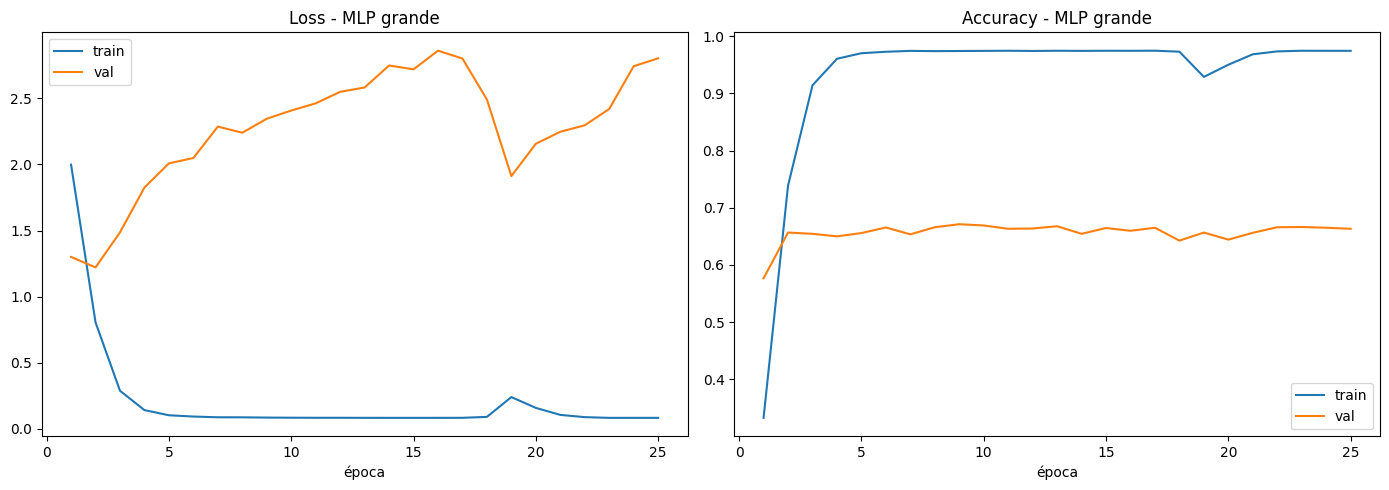

Mínimo de val_loss en la época 2: 1.2214 -> época final: 2.8023
train_acc final: 0.9745 | val_acc final: 0.6633


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep = range(1, EPOCHS_OVERFIT + 1)
axes[0].plot(ep, hist_overfit["train_loss"], label="train")
axes[0].plot(ep, hist_overfit["val_loss"], label="val")
axes[0].set_title("Loss - MLP grande")
axes[1].plot(ep, hist_overfit["train_acc"], label="train")
axes[1].plot(ep, hist_overfit["val_acc"], label="val")
axes[1].set_title("Accuracy - MLP grande")
for ax in axes:
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()

min_ep = int(np.argmin(hist_overfit["val_loss"])) + 1
print(f"Mínimo de val_loss en la época {min_ep}: {min(hist_overfit['val_loss']):.4f} "
      f"-> época final: {hist_overfit['val_loss'][-1]:.4f}")
print(f"train_acc final: {hist_overfit['train_acc'][-1]:.4f} | val_acc final: {hist_overfit['val_acc'][-1]:.4f}")

## Experimento de overfitting

Red de 3 capas de 1024 neuronas (12.4 millones de parámetros, 19 veces más que el mejor MLP), entrenada 25 épocas.

- La loss de validación es mínima en la época 2 y después sube sin parar, de 1.18 a 2.72.
- En train la accuracy llega a 0.97 en la época 5, mientras que en validación queda estancada en 0.67.
- La accuracy de validación no baja aunque la loss se duplique. El modelo no cambia mucho sus respuestas, pero se vuelve cada vez más seguro de las que tiene mal.
- En train no llega al 100% porque el 2.9% de los documentos no tiene ninguna palabra del vocabulario. Todos se ven iguales para el modelo y no los puede distinguir.
- Cada época tardó 0.77 s, unas 3.5 veces más que el mejor MLP.

Es un caso claro de overfitting: la red memoriza el train pero no mejora con datos nuevos.

## 9. Comparación con Regresión Softmax

Para que la comparación sea justa, la regresión softmax (un `MLP` sin capas ocultas) tiene la **misma búsqueda** que el MLP: mismos 30 trials, épocas, pruner, preprocesamiento, optimizadores, rango de `lr` y métrica. Después se entrena con todo el train y con la cantidad de épocas que eligió su validación, igual que el MLP. En esta sección, las curvas de `val` corresponden al **test**.

In [27]:
# Búsqueda para la regresión softmax con el mismo presupuesto y la misma métrica que el MLP:
# mismos trials, épocas, pruner, preprocesamiento, optimizadores y lr.
# Cambia que no hay capas ocultas.
study_sm = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),
)
t0 = time.perf_counter()
study_sm.optimize(lambda t: objective(t, model_kind="softmax"), n_trials=N_TRIALS, timeout=TIMEOUT_S)
search_time_sm = time.perf_counter() - t0

states_sm = pd.Series([t.state.name for t in study_sm.trials]).value_counts()
print(f"\nBúsqueda softmax: {search_time_sm:.1f} s | trials por estado:\n{states_sm.to_string()}")
print("\nMejor val_acc softmax:", round(study_sm.best_value, 4))
print("Mejor época:", study_sm.best_trial.user_attrs["best_epoch"])
print("Mejores hiperparámetros:", study_sm.best_params)

[I 2026-11-19 01:24:29,126] A new study created in memory with name: no-name-7ca306be-05be-43c9-a5e5-ccf136b7dc9b
[I 2026-11-19 01:24:32,104] Trial 0 finished with value: 0.6062748563853292 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'batch_size': 32, 'optimizer': 'rmsprop', 'lr': 0.0007476312062252305, 'rmsprop_alpha': 0.9217587260497535, 'rmsprop_momentum': 0.12554447458683765}. Best is trial 0 with value: 0.6062748563853292.
[I 2026-11-19 01:24:38,867] Trial 1 finished with value: 0.7118868758285462 and parameters: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 5, 'batch_size': 32, 'optimizer': 'adam', 'lr': 0.0030586566669785274, 'adam_beta1': 0.8065338190118916, 'adam_beta2': 0.9908411081676703}. Best is trial 1 with value: 0.7118868758285462.
[I 2026-11-19 01:24:44,287] Trial 2 finished with value: 0.5488289880689351 and parameters: {'r


Búsqueda softmax: 128.6 s | trials por estado:
COMPLETE    22
PRUNED       8

Mejor val_acc softmax: 0.7415
Mejor época: 3
Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'batch_size': 64, 'optimizer': 'adam', 'lr': 0.015293927375080958, 'adam_beta1': 0.9391986079735486, 'adam_beta2': 0.980055047725775}


In [28]:
# Regresión softmax final: mejores hiperparámetros de su búsqueda, todo el train,
# y la cantidad de épocas elegida en validación (igual que el MLP)
def opt_kwargs_from(params):
    if params["optimizer"] == "adam":
        return {"beta1": params["adam_beta1"], "beta2": params["adam_beta2"]}
    if params["optimizer"] == "rmsprop":
        return {"alpha": params["rmsprop_alpha"], "momentum": params["rmsprop_momentum"]}
    return {"momentum": params["sgd_momentum"]}


bsm = study_sm.best_params
SM_EPOCHS = study_sm.best_trial.user_attrs["best_epoch"]
sm_ngram = (1, 1) if bsm["ngram_range"] == "1gram" else (1, 2)
sm_train, sm_test = preprocessed_cache[(bsm["remove_stopwords"], bsm["normalization"])]
X_sm_tr_sp, X_sm_te_sp, _ = vectorize_data(sm_train, sm_test, sm_ngram, bsm["max_features"], bsm["min_df"])
X_sm_tr, y_sm_tr = to_device(X_sm_tr_sp, y_train_full)
X_sm_te, y_sm_te = to_device(X_sm_te_sp, y_test)

torch.manual_seed(SEED)
softmax = MLP(X_sm_tr.shape[1], [], NUM_CLASSES)
opt_sm = make_optimizer(bsm["optimizer"], softmax.parameters(), bsm.get("lr", bsm.get("lr_sgd")),
                        opt_kwargs_from(bsm))
print("Parámetros:", count_params(softmax), "| Épocas:", SM_EPOCHS)

with mlflow.start_run(run_name="softmax_comparacion"):
    mlflow.log_params({**bsm, "epochs": SM_EPOCHS})
    t0 = time.perf_counter()
    hist_sm = train_model(softmax, X_sm_tr, y_sm_tr, X_sm_te, y_sm_te, opt_sm,
                          SM_EPOCHS, bsm["batch_size"], run_name="softmax")
    softmax_time = time.perf_counter() - t0
print(f"Tiempo de entrenamiento final: {softmax_time:.1f} s")

Parámetros: 200020 | Épocas: 3
[softmax] ep 1/3 - train_loss 2.0331 train_acc 0.6054 - val_loss 1.5619 val_acc 0.6686 - 0.24 s
[softmax] ep 2/3 - train_loss 0.9220 train_acc 0.8535 - val_loss 1.2563 val_acc 0.6763 - 0.22 s
[softmax] ep 3/3 - train_loss 0.5852 train_acc 0.8962 - val_loss 1.1567 val_acc 0.6783 - 0.22 s
Tiempo de entrenamiento final: 0.7 s


In [29]:
def resumen_estados(st):
    s = pd.Series([t.state.name for t in st.trials]).value_counts()
    return f"{s.get('COMPLETE', 0)} / {s.get('PRUNED', 0)}"


comparacion = pd.DataFrame({
    "Regresión softmax": {
        "trials (completos / podados)": resumen_estados(study_sm),
        "tiempo de búsqueda (s)": round(search_time_sm, 1),
        "mejor val_acc (búsqueda)": round(study_sm.best_value, 4),
        "parámetros": count_params(softmax),
        "épocas": SM_EPOCHS,
        "test_acc": round(hist_sm["val_acc"][-1], 4),
        "train_acc final": round(hist_sm["train_acc"][-1], 4),
        "s por época": round(float(np.mean(hist_sm["epoch_time"])), 4),
        "tiempo de entrenamiento (s)": round(softmax_time, 2),
    },
    "MLP (mejor de Optuna)": {
        "trials (completos / podados)": resumen_estados(study),
        "tiempo de búsqueda (s)": round(search_time, 1),
        "mejor val_acc (búsqueda)": round(study.best_value, 4),
        "parámetros": count_params(mlp_final),
        "épocas": BEST_EPOCHS,
        "test_acc": round(mlp_test_acc, 4),
        "train_acc final": round(hist_final["train_acc"][-1], 4),
        "s por época": round(float(np.mean(hist_final["epoch_time"])), 4),
        "tiempo de entrenamiento (s)": round(mlp_final_time, 2),
    },
})
print("Ambos modelos: mismo presupuesto de búsqueda y épocas elegidas en validación. 'test_acc' es la última época.")
comparacion

Ambos modelos: mismo presupuesto de búsqueda y épocas elegidas en validación. 'test_acc' es la última época.


,Regresión softmax,MLP (mejor de Optuna)
trials (completos / podados),22 / 8,21 / 9
tiempo de búsqueda (s),128.6,103.1
mejor val_acc (búsqueda),0.7415,0.7229
parámetros,200020,5130772
épocas,3,1
test_acc,0.6783,0.6642
train_acc final,0.8962,0.6396
s por época,0.2292,0.2691
tiempo de entrenamiento (s),0.74,0.31


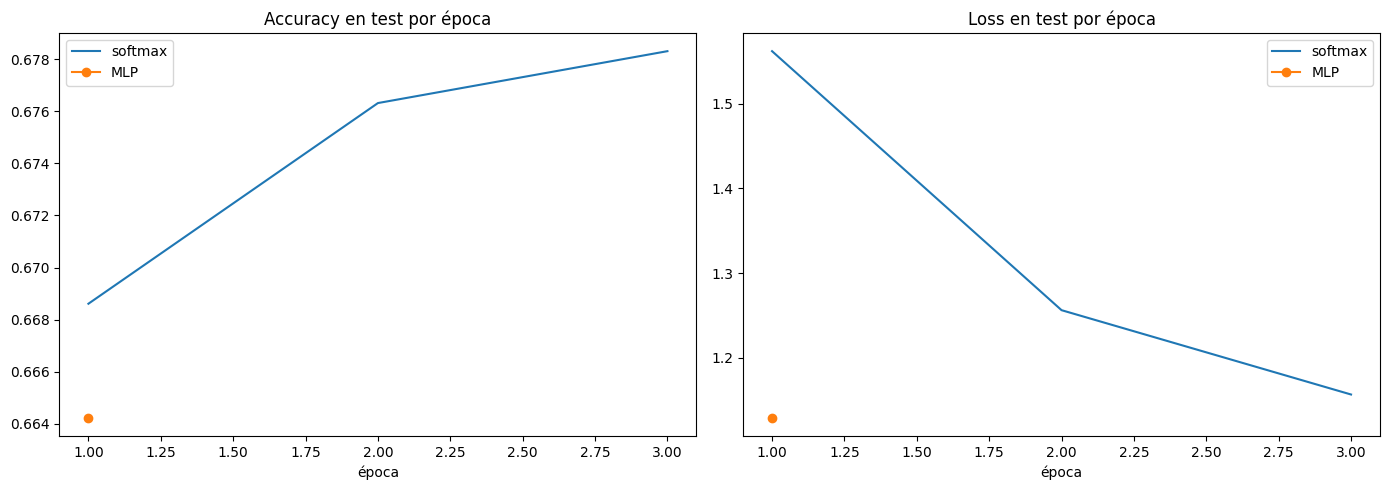

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, SM_EPOCHS + 1), hist_sm["val_acc"], label="softmax")
axes[0].plot(range(1, BEST_EPOCHS + 1), hist_final["val_acc"], "o-", label="MLP")
axes[0].set_title("Accuracy en test por época")
axes[1].plot(range(1, SM_EPOCHS + 1), hist_sm["val_loss"], label="softmax")
axes[1].plot(range(1, BEST_EPOCHS + 1), hist_final["val_loss"], "o-", label="MLP")
axes[1].set_title("Loss en test por época")
for ax in axes:
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()

## Comparación con Regresión Softmax

| | Regresión softmax | MLP |
|---|---|---|
| Trials (completos / podados) | 22 / 8 | 21 / 9 |
| Tiempo de búsqueda | 128.6 s | 103.1 s |
| Mejor val_acc en la búsqueda | 0.7415 | 0.7229 |
| Parámetros | 200020 | 5130772 |
| Épocas | 3 | 1 |
| Test accuracy | 0.6783 | 0.6642 |
| Segundos por época | 0.23 | 0.27 |
| Tiempo de entrenamiento | 0.74 s | 0.31 s |

- Con el mismo presupuesto de búsqueda, **la regresión softmax quedó mejor** que el MLP, tanto en validación como en test.
- El mejor resultado de la softmax (0.7415) es casi igual al del TP anterior (0.7424), aunque la búsqueda cambió. El del MLP, en cambio, cambió mucho entre la entrega anterior (0.7428) y esta (0.7229).
- El MLP tiene unas 26 veces más parámetros y tarda un poco más por época, pero terminó antes porque su validación eligió una sola época.

## 10. Variabilidad entre semillas

In [31]:
# Variabilidad entre semillas: misma configuración, cambia solo la semilla
# (inicialización de los pesos y orden de los lotes)
SEEDS = [0, 1, 2, 3, 4]


def run_seeds(params, hidden, activation, X_tr, y_tr, X_ev, y_ev, epochs, metric):
    accs, t_epoca = [], []
    for s in SEEDS:
        torch.manual_seed(s)
        m = MLP(X_tr.shape[1], hidden, NUM_CLASSES, activation)
        o = make_optimizer(params["optimizer"], m.parameters(), params.get("lr", params.get("lr_sgd")),
                           opt_kwargs_from(params))
        h = train_model(m, X_tr, y_tr, X_ev, y_ev, o, epochs, params["batch_size"], verbose=False)
        accs.append(max(h["val_acc"]) if metric == "mejor" else h["val_acc"][-1])
        t_epoca.append(np.mean(h["epoch_time"]))
    return np.array(accs), np.array(t_epoca)


# Validación: misma métrica que la búsqueda (mejor val_acc en EPOCHS_SEARCH épocas)
X_sm_v_tr_sp, X_sm_v_val_sp = get_search_features(bsm["remove_stopwords"], bsm["normalization"], sm_ngram,
                                                  bsm["max_features"], bsm["min_df"])
X_sm_v_tr, y_sm_v_tr = to_device(X_sm_v_tr_sp, y_tr)
X_sm_v_val, y_sm_v_val = to_device(X_sm_v_val_sp, y_val)

t0 = time.perf_counter()
res = {
    ("MLP", "validación"): run_seeds(bp, best_hidden, bp["activation"], X_tr_o, y_tr_o, X_val_o, y_val_o,
                                     EPOCHS_SEARCH, "mejor"),
    ("Softmax", "validación"): run_seeds(bsm, [], "relu", X_sm_v_tr, y_sm_v_tr, X_sm_v_val, y_sm_v_val,
                                         EPOCHS_SEARCH, "mejor"),
    # Test: igual que el entrenamiento final (todo el train, épocas elegidas en validación, última época)
    ("MLP", "test"): run_seeds(bp, best_hidden, bp["activation"], X_train_t, y_train_t, X_test_t, y_test_t,
                               BEST_EPOCHS, "ultima"),
    ("Softmax", "test"): run_seeds(bsm, [], "relu", X_sm_tr, y_sm_tr, X_sm_te, y_sm_te,
                                   SM_EPOCHS, "ultima"),
}
print(f"Tiempo total: {time.perf_counter() - t0:.1f} s\n")

df_seeds = pd.DataFrame([
    {"modelo": mod, "conjunto": conj, "media": a.mean(), "desvío": a.std(ddof=1),
     "mín": a.min(), "máx": a.max(), "s por época": t.mean()}
    for (mod, conj), (a, t) in res.items()
]).set_index(["modelo", "conjunto"])
print(df_seeds.round(4).to_string())

for conj, n in [("validación", len(y_val)), ("test", len(y_test))]:
    a_mlp, a_sm = res[("MLP", conj)][0], res[("Softmax", conj)][0]
    p = (a_mlp.mean() + a_sm.mean()) / 2
    print(f"\n{conj}: diferencia de medias MLP - softmax = {a_mlp.mean() - a_sm.mean():+.4f} | "
          f"error de muestreo de una accuracy (≈ raíz(p(1-p)/n), n={n}): {np.sqrt(p * (1 - p) / n):.4f}")

Tiempo total: 20.4 s

                     media  desvío     mín     máx  s por época
modelo  conjunto                                               
MLP     validación  0.7179  0.0082  0.7106  0.7304       0.2050
Softmax validación  0.7406  0.0020  0.7371  0.7424       0.1703
MLP     test        0.6665  0.0047  0.6616  0.6719       0.2734
Softmax test        0.6793  0.0010  0.6786  0.6811       0.2092

validación: diferencia de medias MLP - softmax = -0.0227 | error de muestreo de una accuracy (≈ raíz(p(1-p)/n), n=2263): 0.0093

test: diferencia de medias MLP - softmax = -0.0128 | error de muestreo de una accuracy (≈ raíz(p(1-p)/n), n=7532): 0.0054


## Análisis de la variabilidad entre semillas

Se repitieron las dos mejores configuraciones con 5 semillas, cambiando solo la inicialización de los pesos y el orden de los lotes.

| | Validación (media ± desvío) | Test (media ± desvío) |
|---|---|---|
| MLP | 0.718 ± 0.008 | 0.667 ± 0.005 |
| Regresión softmax | 0.741 ± 0.002 | 0.679 ± 0.001 |

- **La softmax es mejor en los dos conjuntos.** La diferencia es de 2.3 puntos en validación y 1.3 en test, en ambos casos unas 2.4 veces el error de muestreo de una accuracy. Además, ninguna de las 5 corridas del MLP superó a ninguna de las de la softmax, ni en validación ni en test.
- **El MLP es mucho más sensible a la semilla:** su desvío es 4 veces mayor en validación y casi 5 veces mayor en test. Como se vio en clase, una red neuronal no garantiza llegar al mismo mínimo y cada corrida puede dar resultados distintos por la inicialización aleatoria. La regresión softmax, en cambio, tiene una función de costo convexa.
- La diferencia entre las dos búsquedas del MLP (0.7428 en la entrega anterior y 0.7229 ahora) es mayor que la variación entre semillas. En este problema la mayor incertidumbre está en la búsqueda de hiperparámetros, no en la semilla.

**Conclusión general.** Con features TF-IDF de alta dimensión, el problema probablemente es casi linealmente separable. Agregar capas ocultas no mejoró sobre la regresión softmax ya que con el mismo presupuesto, la softmax resultó algo mejor y mucho más estable. El MLP sobreajusta en muy pocas épocas.